# P3: Agrupación de estaciones por patrón de uso (Clustering) - MiBici

**Objetivo:** Agrupar las estaciones de MiBici según cómo se usan a lo largo del día y de la semana, y ubicar cada grupo en el mapa de la ciudad.

**Usuario:** Planeación urbana y expansión del sistema.

**Partición:** El modelo se ajusta con los viajes de 2025 y su estabilidad se evalúa con mayo a septiembre de 2026, igual que en P1.

### 1. Librerías y configuración

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import mlflow
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

from proyecto_mibici.config import (
    TRIPS_PROCESSED_PATH,
    STATIONS_PROCESSED_PATH,
    RANDOM_SEED,
    MLFLOW_EXPERIMENT_NAME,
    URI_MLFLOW_TRACKING,
    P3_TRAIN_INICIO,
    P3_TRAIN_FIN,
    P3_TEST_INICIO,
    P3_TEST_FIN,
    P3_VARIABLES,
    P3_K_ELEGIDO,
    P3_MIN_VIAJES_ESTACION,
    P3_DURACION_MAX_MIN,
)

/home/jandro/proyectos/pruebasEquipo20/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-17 09:37:27.959 | INFO     | proyecto_mibici.config:<module>:11 - PROJ_ROOT path is: /home/jandro/proyectos/pruebasEquipo20


### 2. Carga de datos


In [2]:
COLUMNAS = ["viaje_id", "inicio_del_viaje", "fin_del_viaje", "origen_id", "destino_id"]

df_trips = pd.read_parquet(TRIPS_PROCESSED_PATH, columns=COLUMNAS)
df_stations = pd.read_parquet(STATIONS_PROCESSED_PATH)

print(f"Viajes: {len(df_trips):,}")
print(f"Estaciones en catálogo: {len(df_stations):,}")
df_trips.head()

Viajes: 7,894,097
Estaciones en catálogo: 484


,viaje_id,inicio_del_viaje,fin_del_viaje,origen_id,destino_id
0,37162342,2025-01-01 00:00:44,2025-01-01 00:11:29,211,395
1,37162343,2025-01-01 00:04:11,2025-01-01 00:15:07,35,260
2,37162344,2025-01-01 00:05:27,2025-01-01 00:15:23,35,260
3,37162345,2025-01-01 00:07:47,2025-01-01 00:17:42,190,11
4,37162346,2025-01-01 00:08:52,2025-01-01 00:18:10,273,8


Cargamos solo las columnas necesarias para construir el perfil de uso de cada estación. Se omiten columnas con datos personales.

### 3. Limpieza de viajes
Eliminamos los siguientes datos de viajes:
+ viajes duplicados
+ viajes con duración cero 
+ viajes con duración mayor a 3 horas 
+ viajes con estaciones que no existen en el catálogo. 

In [3]:
def limpiar_viajes(df, df_stations, duracion_max_min=180):
    """Elimina los registros que no representan un uso normal del servicio.
    Quita viajes duplicados, viajes con duración cero o mayor a la variable
    duracion_max_min y los viajes con estaciones que no están en el
    catálogo.
    """
    df = df.drop_duplicates(subset="viaje_id")

    duracion = (df["fin_del_viaje"] - df["inicio_del_viaje"]).dt.total_seconds() / 60
    df = df.assign(duracion_min=duracion)
    df = df[(df["duracion_min"] > 0) & (df["duracion_min"] <= duracion_max_min)]

    ids_validos = df_stations["id"]
    df = df[df["origen_id"].isin(ids_validos) & df["destino_id"].isin(ids_validos)]
    return df

In [4]:
df_clean = limpiar_viajes(df_trips, df_stations)

eliminados = len(df_trips) - len(df_clean)
print(f"Viajes limpios: {len(df_clean):,}")
print(f"Eliminados: {eliminados:,} ({eliminados / len(df_trips):.2%})")

Viajes limpios: 7,882,719
Eliminados: 11,378 (0.14%)


Después de la limpieza conservamos 7,882,719 viajes. Se eliminaron 11,378 registros (0.14%) entre duplicados, duraciones inválidas y estaciones fuera del catálogo. La proporción es baja y no altera los patrones de uso que buscamos agrupar.

### 4. Partición temporal
Usamos la misma partición que P1. El modelo se ajusta con los viajes de 2025. La evaluación se realiza 
con los viajes de mayo a septiembre de 2026.

In [ ]:
TRAIN_INICIO, TRAIN_FIN = P3_TRAIN_INICIO, P3_TRAIN_FIN
TEST_INICIO, TEST_FIN = P3_TEST_INICIO, P3_TEST_FIN


def filtrar_periodo(df, inicio, fin):
    """Devuelve los viajes que iniciaron entre inicio (incluido) y fin (excluido)."""
    mask = (df["inicio_del_viaje"] >= inicio) & (df["inicio_del_viaje"] < fin)
    return df[mask]


df_train = filtrar_periodo(df_clean, TRAIN_INICIO, TRAIN_FIN)
df_test = filtrar_periodo(df_clean, TEST_INICIO, TEST_FIN)

print(f"Viajes train: {len(df_train):,}")
print(f"Viajes test:  {len(df_test):,}")

Viajes train: 4,528,798
Viajes test:  1,937,537


### 5. Perfil de uso por estación
Convertimos los viajes en una tabla con una fila por estación. Cada estación está descrita por:
- El rango horario de salida, dividido en 5 secciones (madrugada, mañana, mediodía, tarde y noche).
- La proporción de los viajes en fin de semana.
- La duración media de los viajes.
- El volumen de salidas por día en escala logarítmica.
- La proporción entre llegadas y salidas, que indica si la estación recibe o entrega una bicicleta.

Usamos proporciones en lugar de conteos para comparar el patrón de uso sin importar el tamaño de la estación. Excluimos estaciones con menos de 100 salidas porque su perfil no es confiable.

In [6]:
def construir_perfil_estaciones(df, min_viajes=100):
    """Construye un vector de uso por estación a partir de sus viajes.

    Para P3: agrupar estaciones por cómo se usan (horario, fin de semana,
    volumen y balance entre llegadas y salidas), sin usar su ubicación.
    """
    hora = df["inicio_del_viaje"].dt.hour
    df = df.assign(
        rango_horario=pd.cut(hora, bins=[0, 6, 10, 16, 20, 24], right=False,
                             labels=["madrugada", "manana", "mediodia", "tarde", "noche"]).astype(str),
        fin_de_semana=df["inicio_del_viaje"].dt.dayofweek >= 5,
    )

    salidas = df.groupby("origen_id")
    n_salidas = salidas.size()
    n_llegadas = df.groupby("destino_id").size().reindex(n_salidas.index, fill_value=0)
    n_dias = df["inicio_del_viaje"].dt.normalize().nunique()

    perfil = (
        pd.crosstab(df["origen_id"], df["rango_horario"], normalize="index")
        .add_prefix("pct_")
        .rename_axis(columns=None)
    )
    perfil["pct_fin_de_semana"] = salidas["fin_de_semana"].mean()
    perfil["duracion_media"] = salidas["duracion_min"].mean()
    perfil["viajes_dia_log"] = np.log1p(n_salidas / n_dias)
    perfil["balance_neto"] = (n_llegadas - n_salidas) / (n_llegadas + n_salidas)

    return perfil[n_salidas >= min_viajes]

In [7]:
perfil_train = construir_perfil_estaciones(df_train)
perfil_test = construir_perfil_estaciones(df_test)

print(f"Estaciones con perfil en train: {len(perfil_train)}")
print(f"Estaciones con perfil en test:  {len(perfil_test)}")
perfil_train.describe().round(2)

Estaciones con perfil en train: 371
Estaciones con perfil en test:  469


,pct_madrugada,pct_manana,pct_mediodia,pct_noche,pct_tarde,pct_fin_de_semana,duracion_media,viajes_dia_log,balance_neto
count,371.00,371.00,371.00,371.00,371.00,371.00,371.00,371.00,371.00
mean,0.02,0.23,0.33,0.12,0.30,0.21,11.36,3.21,-0.02
std,0.01,0.08,0.06,0.04,0.07,0.05,1.89,0.83,0.12
min,0.00,0.04,0.20,0.04,0.12,0.07,5.89,0.29,-0.35
25%,0.01,0.17,0.30,0.09,0.25,0.18,10.17,2.61,-0.10
50%,0.01,0.23,0.33,0.12,0.29,0.20,11.12,3.23,-0.02
75%,0.02,0.29,0.37,0.14,0.34,0.23,12.57,3.82,0.03
max,0.09,0.46,0.54,0.26,0.55,0.51,17.15,5.48,0.51


Obtuvimos el perfil de 371 estaciones en el periodo de entrenamiento y de 469 en el de prueba. La diferencia corresponde a estaciones que comenzaron a operar en 2026. En la evaluación, el modelo entrenado con 2025 asigna estas estaciones nuevas al grupo más parecido.

Las estaciones difieren de forma clara en su patrón de uso.En este caso, la proporción de salidas en la mañana va de 4% a 46%, la proporción de viajes en fin de semana va de 7% a 51% y el balance neto va de -0.35 a 0.51. El rango de madrugada concentra solo 2% de los viajes y casi no varía entre estaciones.

### 6. Selección y escalado de variables
Quitamos la proporción de madrugada porque casi no varía entre estaciones. Además, los cinco rangos horarios suman 1, así que uno de ellos siempre es redundante. Después escalamos las variables para que todas pesen lo mismo en el cálculo de distancias de KMeans.

In [ ]:
VARIABLES = P3_VARIABLES

scaler = StandardScaler()
X_train = scaler.fit_transform(perfil_train[VARIABLES])
X_test = scaler.transform(perfil_test[VARIABLES])

print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")

X_train: (371, 8)
X_test:  (469, 8)


In [9]:
def entrenar_kmeans(X, k, semilla=RANDOM_SEED):
    """Ajusta KMeans con k grupos sobre el perfil de uso escalado de las estaciones."""
    modelo = KMeans(n_clusters=k, n_init=10, random_state=semilla)
    modelo.fit(X)
    return modelo


def evaluar_clusters(X, etiquetas):
    """Calcula silhouette (mayor es mejor) y Davies-Bouldin (menor es mejor)."""
    return {
        "silhouette": silhouette_score(X, etiquetas),
        "davies_bouldin": davies_bouldin_score(X, etiquetas),
    }

In [10]:
K_BASELINE = 4
modelo_base = entrenar_kmeans(X_train, K_BASELINE)

metricas_base = pd.DataFrame({
    "train": evaluar_clusters(X_train, modelo_base.labels_),
    "test": evaluar_clusters(X_test, modelo_base.predict(X_test)),
})
metricas_base.round(3)

,train,test
silhouette,0.187,0.182
davies_bouldin,1.561,1.535


In [11]:
def buscar_k(X, k_min=2, k_max=10):
    """Entrena KMeans para cada k y devuelve sus métricas.
    Elige el número de grupos con un criterio medible en lugar de fijarlo a mano.
    """
    resultados = []
    for k in range(k_min, k_max + 1):
        modelo = entrenar_kmeans(X, k)
        metricas = evaluar_clusters(X, modelo.labels_)
        resultados.append({"k": k, **metricas})
    return pd.DataFrame(resultados).set_index("k")

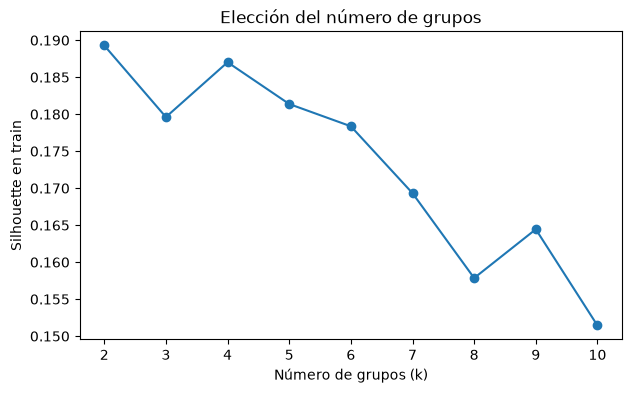

,silhouette,davies_bouldin
k,,
2,0.189,1.890
3,0.180,1.732
4,0.187,1.561
5,0.181,1.555
6,0.178,1.505
7,0.169,1.567
8,0.158,1.523
9,0.164,1.521
10,0.151,1.520


In [12]:
busqueda_k = buscar_k(X_train)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(busqueda_k.index, busqueda_k["silhouette"], marker="o")
ax.set_xlabel("Número de grupos (k)")
ax.set_ylabel("Silhouette en train")
ax.set_title("Elección del número de grupos")
plt.show()

busqueda_k.round(3)

### 7. Baseline: agrupación por municipio
Como línea base agrupamos las estaciones por el municipio al que pertenecen, sin usar ningún modelo. Es la forma en que se organizaría la red sin análisis de uso. Evaluamos qué tan bien describe esa agrupación el perfil de uso con dos métricas internas: el coeficiente de silhouette, que va de -1 a 1 y es mejor mientras más alto, y el índice de Davies-Bouldin, que es mejor mientras más bajo.

In [13]:
def evaluar_clusters(X, etiquetas):
    """Calcula silhouette (mayor es mejor) y Davies-Bouldin (menor es mejor)."""
    return {
        "silhouette": silhouette_score(X, etiquetas),
        "davies_bouldin": davies_bouldin_score(X, etiquetas),
    }

In [14]:
municipio = df_stations.set_index("id")["municipality_code"]
etiquetas_mun_train = municipio.loc[perfil_train.index]
etiquetas_mun_test = municipio.loc[perfil_test.index]

print(etiquetas_mun_train.value_counts())

metricas_baseline = pd.DataFrame({
    "train": evaluar_clusters(X_train, etiquetas_mun_train),
    "test": evaluar_clusters(X_test, etiquetas_mun_test),
})
metricas_baseline.round(3)

municipality_code
GDL    282
ZPN     74
TLQ     15
Name: count, dtype: int64


,train,test
silhouette,0.050,0.019
davies_bouldin,3.348,3.712


### 8. Búsqueda del número de grupos
Entrenamos KMeans con k de 2 a 10 y comparamos el silhouette y el índice de Davies-Bouldin de cada uno en train.

In [ ]:
def entrenar_kmeans(X, k, semilla=RANDOM_SEED):
    """Ajusta KMeans con k grupos sobre el perfil de uso escalado de las estaciones."""
    modelo = KMeans(n_clusters=k, n_init=10, random_state=semilla)
    modelo.fit(X)
    return modelo


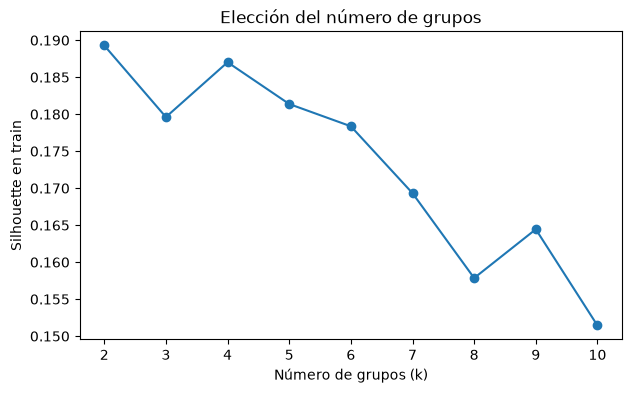

,silhouette,davies_bouldin
k,,
2,0.189,1.890
3,0.180,1.732
4,0.187,1.561
5,0.181,1.555
6,0.178,1.505
7,0.169,1.567
8,0.158,1.523
9,0.164,1.521
10,0.151,1.520


In [16]:
busqueda_k = buscar_k(X_train)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(busqueda_k.index, busqueda_k["silhouette"], marker="o")
ax.set_xlabel("Número de grupos (k)")
ax.set_ylabel("Silhouette en train")
ax.set_title("Elección del número de grupos")
plt.show()

busqueda_k.round(3)

El silhouette es bajo para todos los valores de k (entre 0.15 y 0.19), lo que indica que las estaciones forman un continuo de perfiles más que grupos claramente separados. Elegimos k = 4 ya que su silhouette (0.187) es prácticamente igual al de k = 2 (0.189), su índice de Davies-Bouldin es mucho mejor (1.56 frente a 1.89) y cuatro grupos ofrecen una información que es más útil. También se puede observar que a partir de k = 7 las métricas empeoran.

### 9. Modelo candidato de KMeans con 4 grupos
Entrenamos KMeans con el número de grupos elegido y lo comparamos contra la agrupación por municipio en train y en test. En test, el modelo entrenado con 2025 asigna cada estación de 2026 al grupo más cercano, incluidas las estaciones nuevas.

In [ ]:
K_ELEGIDO = P3_K_ELEGIDO
modelo_kmeans = entrenar_kmeans(X_train, K_ELEGIDO)
etiquetas_train = modelo_kmeans.labels_
etiquetas_test = modelo_kmeans.predict(X_test)

metricas_kmeans = pd.DataFrame({
    "train": evaluar_clusters(X_train, etiquetas_train),
    "test": evaluar_clusters(X_test, etiquetas_test),
})

comparacion = pd.concat(
    {"baseline_municipio": metricas_baseline, "kmeans_k4": metricas_kmeans}, axis=1
)
comparacion.round(3)

baseline_municipio        kmeans_k4       
                            train   test     train   test
silhouette                  0.050  0.019     0.187  0.182
davies_bouldin              3.348  3.712     1.561  1.535

El KMeans elegido describe el patrón de uso de las estaciones mucho mejor que la agrupación por municipio. Su valor de silhouette es casi cuatro veces mayor y su índice de Davies-Bouldin es menos de la mitad. La agrupación por municipio tiene un silhouette cercano a cero, lo que indica que estaciones del mismo municipio se usan de maneras muy distintas.

Los grupos aprendidos con 2025 se mantienen en el año 2026. Para la sección de test, el valor de silhouette disminuye casi nulamente y el índice de Davies-Bouldin mejora ligeramente. Esto incluye las estaciones que comenzaron a operar en 2026, que no formaron parte del entrenamiento.

### 10. Perfil de cada grupo
Calculamos el promedio de cada variable dentro de cada grupo, en sus unidades originales, para interpretar qué tipo de estación representa cada uno.

In [18]:
perfil_grupos = perfil_train[VARIABLES].assign(grupo=etiquetas_train)

resumen_grupos = perfil_grupos.groupby("grupo").mean().round(2)
resumen_grupos["n_estaciones"] = perfil_grupos["grupo"].value_counts()
resumen_grupos

,pct_manana,pct_mediodia,pct_tarde,pct_noche,pct_fin_de_semana,duracion_media,viajes_dia_log,balance_neto,n_estaciones
grupo,,,,,,,,,
0,0.20,0.43,0.27,0.10,0.28,13.12,2.80,-0.05,32
1,0.19,0.35,0.31,0.14,0.20,10.74,3.84,0.01,135
2,0.32,0.31,0.24,0.10,0.20,10.42,2.88,0.03,126
3,0.18,0.30,0.38,0.12,0.19,13.24,2.82,-0.14,78


### 11. Ubicación de los grupos en la ciudad
Ubicamos cada estación con su latitud y longitud del catálogo y la coloreamos según su grupo.

In [19]:
def graficar_mapa_grupos(perfil, etiquetas, df_stations, titulo):
    """Dibuja las estaciones en el mapa coloreadas por grupo.

    Para P3: responder dónde se ubica cada tipo de estación en la ciudad.
    """
    coords = df_stations.set_index("id").loc[perfil.index, ["latitude", "longitude"]]

    fig, ax = plt.subplots(figsize=(7, 7))
    puntos = ax.scatter(coords["longitude"], coords["latitude"], c=etiquetas, cmap="tab10", s=18)
    ax.legend(*puntos.legend_elements(), title="Grupo")
    ax.set_xlabel("Longitud")
    ax.set_ylabel("Latitud")
    ax.set_title(titulo)
    return fig

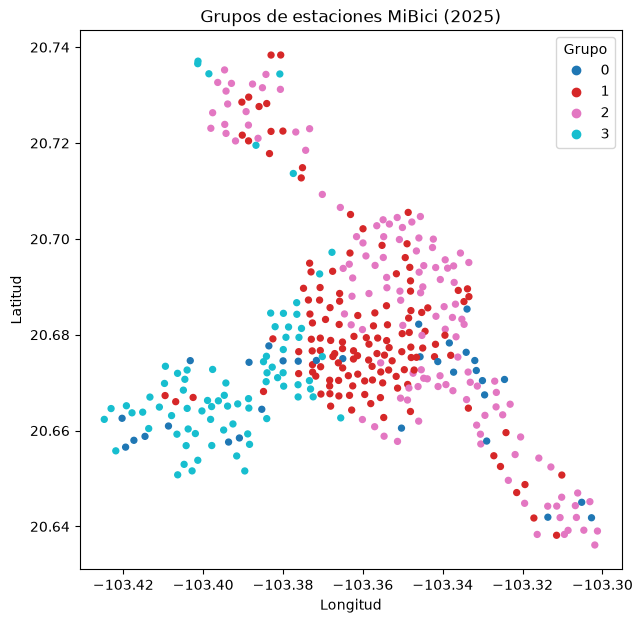

In [20]:
fig_mapa = graficar_mapa_grupos(
    perfil_train, etiquetas_train, df_stations, "Grupos de estaciones MiBici (2025)"
)
plt.show()

Los cuatro grupos tienen perfiles de uso distintos:

- **Grupo 1, alta demanda:** Es el grupo con el mayor volumen de viajes, con la mayor proporción de viajes nocturnos, con viajes de duración corta y un balance entre las llegadas y salidas.
- **Grupo 2, salida matutina:** Es el grupo con la mayor proporción de salidas en la mañana y los viajes más cortos. Su patrón corresponde a zonas de origen de viajes al inicio del día.
- **Grupo 3, salida vespertina:** Es el grupo con la mayor proporción de salidas en la tarde y el balance más negativo, es decir, que entrega más bicicletas de las que recibe. Su patrón corresponde a zonas de trabajo o comercio.
- **Grupo 0, uso recreativo:** Es el grupo con la mayor proporción de viajes al mediodía y en fin de semana, con los viajes más largos.

### 12. Registro en MLflow
Registramos dos runs en el experimento del equipo: el baseline por municipio y el modelo KMeans con 4 grupos. Cada run guarda los parámetros necesarios para reproducirlo, las métricas en train y test, etiquetas con el equipo, la pregunta y el commit de Git, y el mapa de grupos como artefacto.

In [21]:
import json
import subprocess

from proyecto_mibici.config import MANIFEST_PATH


def obtener_commit():
    """Devuelve el hash corto del commit actual de Git para ligar el run con el código."""
    return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], text=True).strip()


def obtener_version_datos():
    """Devuelve los primeros 12 caracteres del hash SHA256 de trips.parquet según el manifiesto."""
    with open(MANIFEST_PATH, encoding="utf-8") as f:
        return json.load(f)["trips"]["sha256"][:12]


def aplanar_metricas(tabla):
    """Convierte la tabla de métricas (filas: métrica, columnas: train/test) en nombres como test_silhouette."""
    return {
        f"{conjunto}_{metrica}": float(valor)
        for conjunto in tabla.columns
        for metrica, valor in tabla[conjunto].items()
    }

In [ ]:
mlflow.set_tracking_uri(URI_MLFLOW_TRACKING)
mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)

PARAMS_COMUNES = {
    "pregunta": "P3",
    "train_inicio": TRAIN_INICIO,
    "train_fin": TRAIN_FIN,
    "test_inicio": TEST_INICIO,
    "test_fin": TEST_FIN,
    "datos_version": obtener_version_datos(),
    "semilla": RANDOM_SEED,
    "variables": ", ".join(VARIABLES),
    "min_viajes_estacion": 100,
    "duracion_max_min": 180,
}
TAGS_COMUNES = {"equipo": "20", "pregunta": "P3", "git_commit": obtener_commit()}


def registrar_run(nombre_run, params_modelo, tabla_metricas, figura, tabla_extra=None):
    """Registra un run de P3 con parámetros, métricas, etiquetas y artefactos."""
    with mlflow.start_run(run_name=nombre_run):
        mlflow.set_tags(TAGS_COMUNES)
        mlflow.log_params({**PARAMS_COMUNES, **params_modelo})
        mlflow.log_metrics(aplanar_metricas(tabla_metricas))
        mlflow.log_figure(figura, "mapa_grupos.png")
        if tabla_extra is not None:
            mlflow.log_text(tabla_extra.to_csv(), "resumen_grupos.csv")

2026/10/17 09:37:35 INFO mlflow.tracking.fluent: Experiment with name 'mibici-equipo20' does not exist. Creating a new experiment.


🏃 View run p3-baseline-municipio at: http://127.0.0.1:8080/#/experiments/1/runs/37e9a56b0d384e388d28ee320de6b2f4
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/1
🏃 View run p3-kmeans-k4 at: http://127.0.0.1:8080/#/experiments/1/runs/3ec20a1bee4b4378bae850fab3699d99
🧪 View experiment at: http://127.0.0.1:8080/#/experiments/1


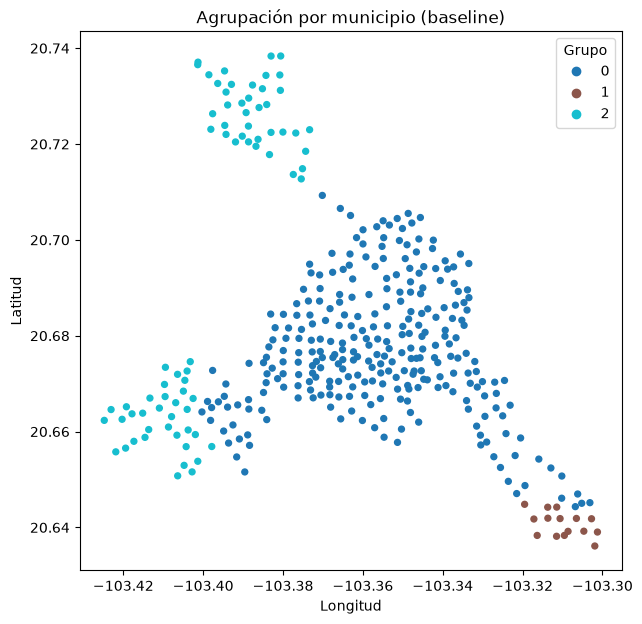

In [23]:
fig_mapa_base = graficar_mapa_grupos(
    perfil_train,
    etiquetas_mun_train.astype("category").cat.codes,
    df_stations,
    "Agrupación por municipio (baseline)",
)

registrar_run(
    "p3-baseline-municipio",
    {"modelo": "AgrupacionMunicipio"},
    metricas_baseline,
    fig_mapa_base,
)

registrar_run(
    "p3-kmeans-k4",
    {"modelo": "KMeans", "n_clusters": K_ELEGIDO, "n_init": 10},
    metricas_kmeans,
    fig_mapa,
    resumen_grupos,
)